# Module 7 Lab 2
Linear regression modeling for restaurant ratings

In [1]:
#Import Libraries
import pandas as pd
import seaborn as sns
import numpy as np
import scipy
import matplotlib.pyplot as plt
import statsmodels.api as sm
import sklearn

In [2]:
#Import database
import pandas as pd
originaldf = pd.read_csv("ratings.tsv", sep="\t")
df = originaldf

In [3]:
df.shape

(15, 5)

In [4]:
df.head()

,restaurant,food,ambience,service,rating
0,1,85,82,89,78
1,2,80,90,80,85
2,3,83,86,83,85
3,4,70,96,75,72
4,5,68,80,78,75


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   restaurant  15 non-null     int64
 1   food        15 non-null     int64
 2   ambience    15 non-null     int64
 3   service     15 non-null     int64
 4   rating      15 non-null     int64
dtypes: int64(5)
memory usage: 732.0 bytes


In [6]:
df.describe()

,restaurant,food,ambience,service,rating
count,15.000000,15.000000,15.000000,15.000000,15.000000
mean,8.000000,73.133333,81.733333,75.133333,73.066667
std,4.472136,6.555986,9.786774,8.069932,8.319226
min,1.000000,64.000000,68.000000,56.000000,54.000000
25%,4.500000,68.500000,71.000000,73.500000,70.500000
50%,8.000000,72.000000,82.000000,78.000000,74.000000
75%,11.500000,77.500000,90.000000,78.000000,77.500000
max,15.000000,85.000000,96.000000,89.000000,85.000000


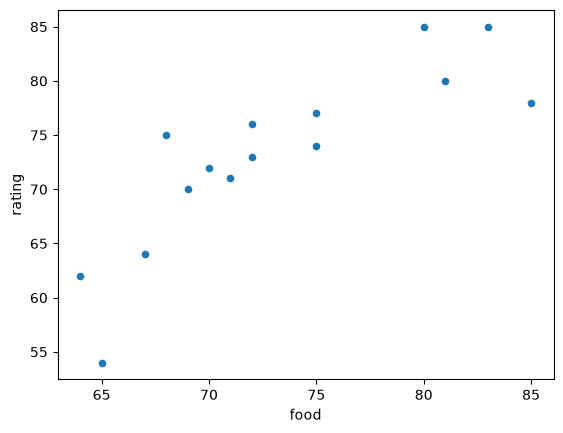

In [7]:
#Check out some plots
df.plot.scatter(x='food', y='rating')
plt.show()

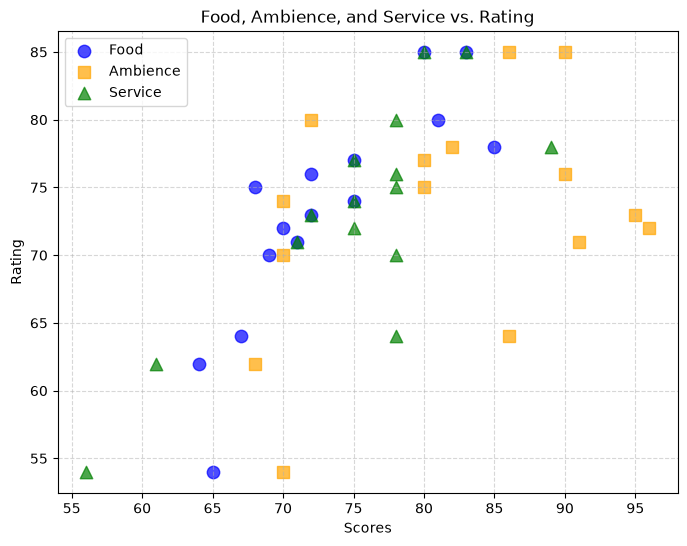

In [8]:
#Wanted to see all the data at once so asked Gemini for the code.

plt.figure(figsize=(8, 6))

# Loop through each predictor variable and plot against rating
for col, color, marker in zip(['food', 'ambience', 'service'], ['blue', 'orange', 'green'], ['o', 's', '^']):
    plt.scatter(df[col], df['rating'], color=color, label=col.capitalize(), alpha=0.7, marker=marker, s=80)

plt.xlabel('Scores')
plt.ylabel('Rating')
plt.title('Food, Ambience, and Service vs. Rating')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Sample hand calculated slopes
The plan is run linear regression on each of the three rating that impact the overall rating to see which aligns most closely with the overall rating.

This will be a linear regression to find the best correlation:
y = mn*xn + bn

n = 1 for food
n = 2 for ambience
n = 3 for service
y = rating

Hand Calculations:

slope = m = change in y over change in x
Calculate the slope and then the linear regression to find the fit.

Change in (max-min):
+ Food: 85-64 = 21
+ Ambience: 96-68 = 28
+ Service: 89-56 = 33
+ Rating: 85-54 =31

Slope (change in y divided by change in x)
+ Food: 31/21 = 1.48
+ Ambience: 31/28 = 1.1
+ Service: 31/33 = 0.94


These hand calculated slopes using simply the min and max show excellent correlation, near one to one for ambience and service (1.1 and 0.96, respectively). Whereas food is further off in correlation.

# Slopes Calculated with all the data using sklearn

In [9]:
# Split and Teach using a 70/30 split
from sklearn.model_selection import train_test_split
X = df[["food", "ambience", "service"]]
y = df["rating"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

In [10]:
# Test the fit
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
print(model.score(X_test, y_test))

0.5754173218285633


In [11]:
# Slope (model.coefficient) and intercept (model.intercept)
print(model.coef_, model.intercept_)

[0.95676835 0.07401426 0.20380826] -17.214438121026177


The model's coefficient (slope) for food rating to overall rating is 0.96 which is almost a one to one ratio. A very good predictor of overall rating based on food rating. The model's slope for service with the second best at 0.2 and the slope for ambience is the worst, meaning the ambience rating is a poor predictor for the overall rating.

https://github.com/acamend/cs82a-portfolio